# Deep learning practical 2

## Mathematical notation

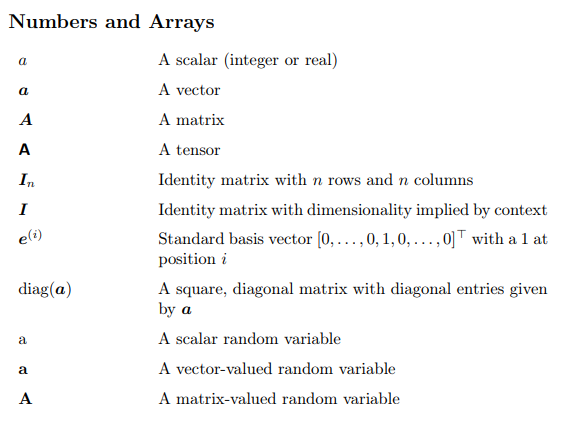

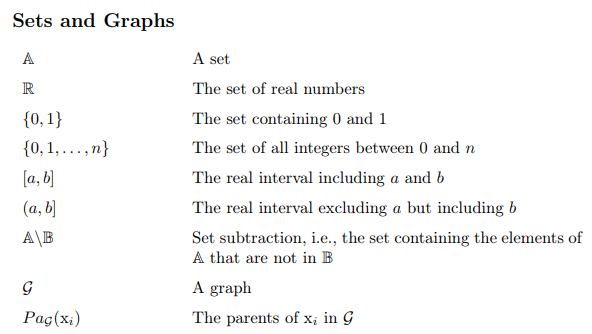

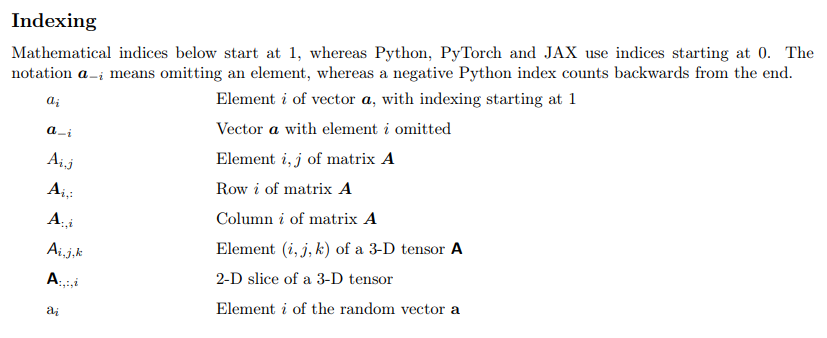

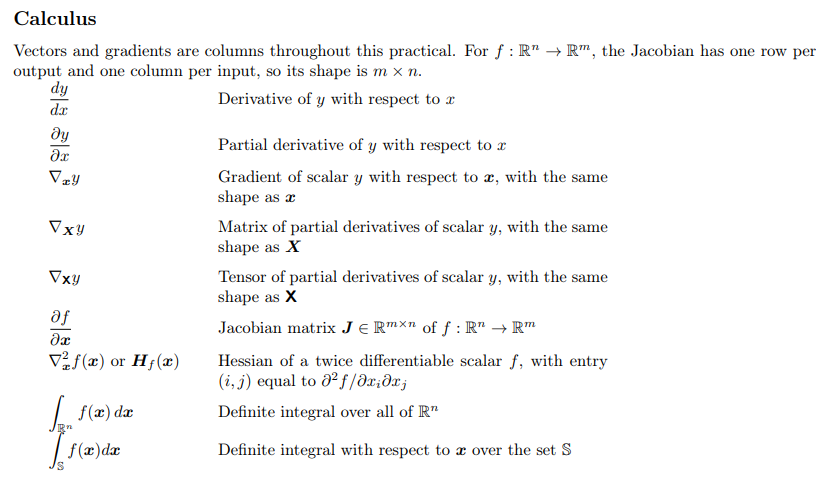

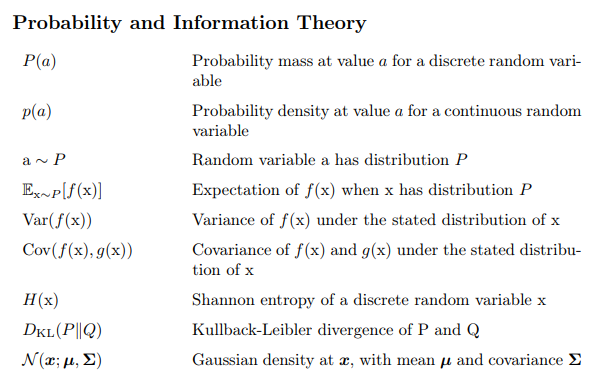

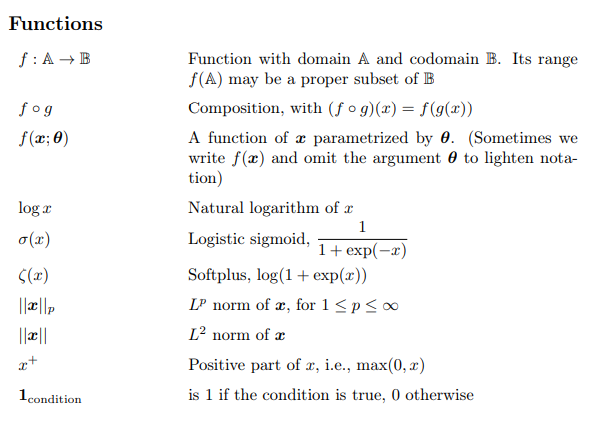

## Derivatives

The derivative measures how a function's output changes in response to a small change in its input.

In deep learning, derivatives of the loss tell us how to adjust a neural networ's parameters to reduce prediction error locally.

A partial derivative varies one input while holding the others fixed.

A Jacobian is a matrix containing the partial derivatives of a function with respect to each of its input variables.

It describes how changes in the inputs of a function affect each of its outputs.

In [1]:
import torch
from torch import nn
# Run the plotting-functions cell first in dl-practical2.py.

torch.set_num_threads(2)
torch.manual_seed(42)

def spirals(n):
    t = torch.linspace(0, 1, n)
    angle = 2.5 * torch.pi * t
    radius = 0.15 + 0.8 * t
    arm = torch.stack((radius * angle.cos(), radius * angle.sin()), dim=1)
    X = torch.cat((arm, -arm)) + 0.01 * torch.randn(2 * n, 2)
    y = torch.cat((torch.ones(n, 1), -torch.ones(n, 1)))
    return X, y

X, y = spirals(128)
X_test, y_test = spirals(512)

Exercise: Sketch the shapes of arm, X and y as rows and columns. Which axis does stack create, and which
existing axis does cat extend? What shape would model(X) - y have if y were (256,) instead of (256, 1)?

arm has 128 rows and two coordinate columns. Stacking the two coordinate vectors creates that column axis,
while concatenating the arm with its reflection extends the row axis to give X shape (256, 2). There is one label
per row, so y has shape (256, 1).
If y instead had shape (256,), broadcasting against the (256, 1) predictions would produce a (256, 256) array.
This would compare each prediction with every label, rather than pairing each point with its own label.

In [3]:
torch.manual_seed(7)
width = 32
model = nn.Sequential(
nn.Linear(2, width), nn.Tanh(),
nn.Linear(width, width), nn.Tanh(),
nn.Linear(width, 2), nn.Tanh(),
nn.Linear(2, 1),
)
print(sum(p.numel() for p in model.parameters()), "parameters")


1221 parameters


Exercise: Calculate the number of parameters in each Linear layer and check their total against the
program's output. Which operations have no learned parameters?

1st layer: 2 $\times$ 32 = 64 parameters  
2nd layer: 32 $\times$ 32 = 1024 parameters  
3rd layer: 32 $\times$ 2 = 64 parameters  
4th layer: no learned parameters

Total = 64 + 1024 + 64 = 1152

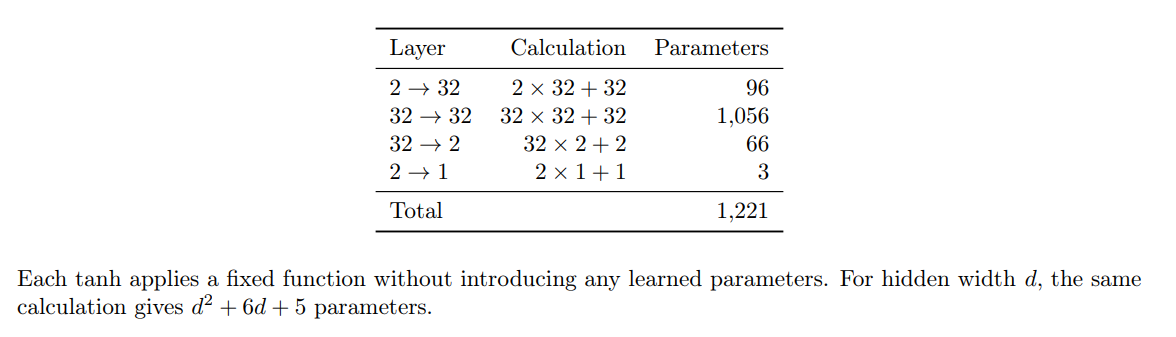

In [5]:
score = model(X)
loss = (score - y).square().mean()
loss.backward()
print(model[-1].weight.grad)
model.zero_grad()

tensor([[0.0953, 0.0196]])


Use `model[:-1](X)` to obtain the hidden features and check the printed derivatives against the
expression above. Has backward() changed the weights? Explain the need to clear gradients before calculating
them again.

In [6]:
model[:-1](X)

tensor([[ 0.1294,  0.1135],
        [ 0.1309,  0.1111],
        [ 0.1298,  0.1129],
        [ 0.1295,  0.1129],
        [ 0.1273,  0.1150],
        [ 0.1281,  0.1151],
        [ 0.1271,  0.1163],
        [ 0.1257,  0.1182],
        [ 0.1249,  0.1231],
        [ 0.1244,  0.1202],
        [ 0.1235,  0.1207],
        [ 0.1221,  0.1246],
        [ 0.1216,  0.1255],
        [ 0.1212,  0.1242],
        [ 0.1215,  0.1214],
        [ 0.1206,  0.1215],
        [ 0.1213,  0.1173],
        [ 0.1194,  0.1205],
        [ 0.1200,  0.1188],
        [ 0.1199,  0.1170],
        [ 0.1195,  0.1130],
        [ 0.1200,  0.1111],
        [ 0.1189,  0.1102],
        [ 0.1201,  0.1058],
        [ 0.1202,  0.1035],
        [ 0.1197,  0.1033],
        [ 0.1199,  0.0995],
        [ 0.1211,  0.0938],
        [ 0.1214,  0.0895],
        [ 0.1212,  0.0887],
        [ 0.1214,  0.0854],
        [ 0.1224,  0.0786],
        [ 0.1226,  0.0788],
        [ 0.1232,  0.0754],
        [ 0.1247,  0.0665],
        [ 0.1253,  0

In [8]:
model.zero_grad()
score = model(X)
loss = ((score-y)**2).mean()
loss.backward()
H = model[:-1](X).detach()
manual = 2*(score.detach()-y).T @ H / len(X)
torch.testing.assert_close(model[-1].weight.grad, manual)
H

tensor([[ 0.1294,  0.1135],
        [ 0.1309,  0.1111],
        [ 0.1298,  0.1129],
        [ 0.1295,  0.1129],
        [ 0.1273,  0.1150],
        [ 0.1281,  0.1151],
        [ 0.1271,  0.1163],
        [ 0.1257,  0.1182],
        [ 0.1249,  0.1231],
        [ 0.1244,  0.1202],
        [ 0.1235,  0.1207],
        [ 0.1221,  0.1246],
        [ 0.1216,  0.1255],
        [ 0.1212,  0.1242],
        [ 0.1215,  0.1214],
        [ 0.1206,  0.1215],
        [ 0.1213,  0.1173],
        [ 0.1194,  0.1205],
        [ 0.1200,  0.1188],
        [ 0.1199,  0.1170],
        [ 0.1195,  0.1130],
        [ 0.1200,  0.1111],
        [ 0.1189,  0.1102],
        [ 0.1201,  0.1058],
        [ 0.1202,  0.1035],
        [ 0.1197,  0.1033],
        [ 0.1199,  0.0995],
        [ 0.1211,  0.0938],
        [ 0.1214,  0.0895],
        [ 0.1212,  0.0887],
        [ 0.1214,  0.0854],
        [ 0.1224,  0.0786],
        [ 0.1226,  0.0788],
        [ 0.1232,  0.0754],
        [ 0.1247,  0.0665],
        [ 0.1253,  0

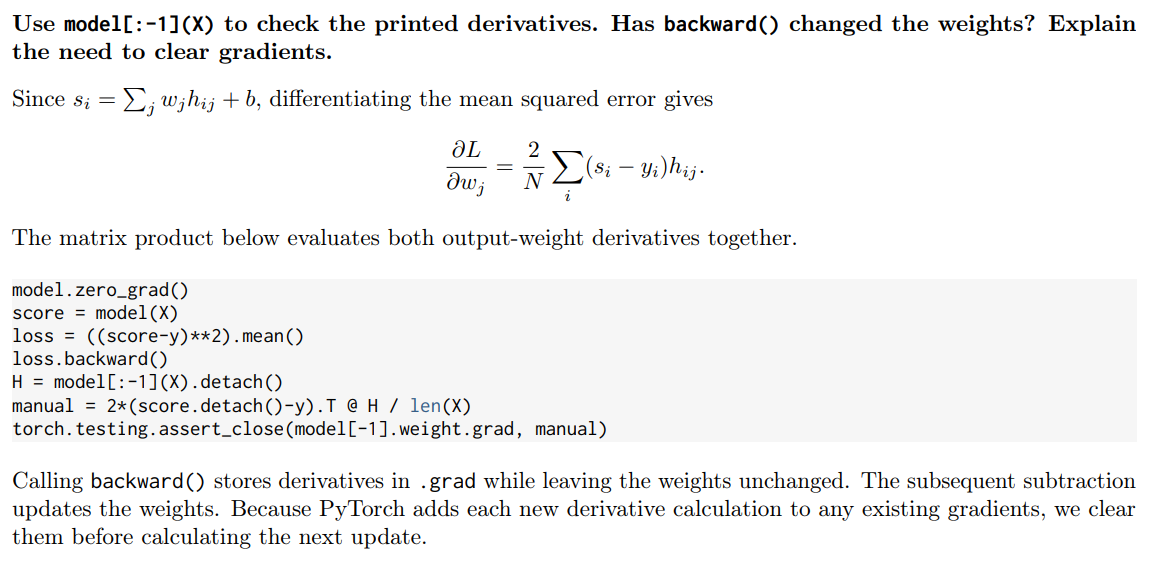